<a href="https://colab.research.google.com/github/shneha405/RealEstate-/blob/main/Real_Estate_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving merged_houseprice_regression_classification.xlsx to merged_houseprice_regression_classification (1).xlsx


In [ ]:
import io

file_name = list(uploaded.keys())[0]

excel_file = pd.ExcelFile(io.BytesIO(uploaded[file_name]))

print("Available sheets:")
print(excel_file.sheet_names)

Available sheets:
['Regression+Class', 'RealEstate_Valuation']


In [ ]:
df = pd.read_excel(
    io.BytesIO(uploaded[file_name]),
    sheet_name="Regression+Class"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (500, 15)

Column Names:
['Property_ID', 'Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Location_Score', 'School_Score', 'Current_Price', 'Price_Year_1', 'Price_Year_2', 'Price_Year_3', 'Price_Year_4', 'Price_After_5_Years', 'Price_Category']

First 5 Records:


,Property_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location_Score,School_Score,Current_Price,Price_Year_1,Price_Year_2,Price_Year_3,Price_Year_4,Price_After_5_Years,Price_Category
0,1,2751,3,4,3,1989,54,58,624636,656833,690689,726290,763726,803092,Medium
1,2,3322,5,1,1,2019,62,78,694237,729166,765853,804385,844856,887363,Medium
2,3,4765,3,3,2,1989,57,50,771778,803688,836917,871520,907554,945078,Medium
3,4,4512,2,2,3,2004,57,90,792597,854577,921404,993457,1071144,1154906,High
4,5,2436,3,1,1,1987,76,69,580257,612034,645552,680905,718194,757525,Low


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Property_ID          500 non-null    int64 
 1   Area_sqft            500 non-null    int64 
 2   Bedrooms             500 non-null    int64 
 3   Bathrooms            500 non-null    int64 
 4   Floors               500 non-null    int64 
 5   Year_Built           500 non-null    int64 
 6   Location_Score       500 non-null    int64 
 7   School_Score         500 non-null    int64 
 8   Current_Price        500 non-null    int64 
 9   Price_Year_1         500 non-null    int64 
 10  Price_Year_2         500 non-null    int64 
 11  Price_Year_3         500 non-null    int64 
 12  Price_Year_4         500 non-null    int64 
 13  Price_After_5_Years  500 non-null    int64 
 14  Price_Category       500 non-null    object
dtypes: int64(14), object(1)
memory usage: 58.7+ KB


In [ ]:
display(df.describe())

,Property_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location_Score,School_Score,Current_Price,Price_Year_1,Price_Year_2,Price_Year_3,Price_Year_4,Price_After_5_Years
count,500.000000,500.000000,500.000000,500.0000,500.000000,500.000000,500.00000,500.000000,5.000000e+02,5.000000e+02,5.000000e+02,5.000000e+02,5.000000e+02,5.000000e+02
mean,250.500000,2979.942000,3.022000,2.5020,1.878000,2000.856000,75.13800,69.182000,6.603022e+05,7.025748e+05,7.478032e+05,7.962087e+05,8.480306e+05,9.035266e+05
std,144.481833,1198.840073,1.414751,1.1011,0.822477,12.905051,14.60471,17.617196,1.544186e+05,1.650520e+05,1.775613e+05,1.921851e+05,2.091685e+05,2.287644e+05
min,1.000000,802.000000,1.000000,1.0000,1.000000,1980.000000,50.00000,40.000000,2.956020e+05,3.134080e+05,3.322860e+05,3.523010e+05,3.735220e+05,3.960210e+05
25%,125.750000,1956.250000,2.000000,2.0000,1.000000,1989.000000,62.00000,53.750000,5.390245e+05,5.700972e+05,6.130052e+05,6.446658e+05,6.851585e+05,7.221465e+05
50%,250.500000,2999.500000,3.000000,3.0000,2.000000,2001.000000,75.50000,68.500000,6.639505e+05,7.053170e+05,7.530600e+05,7.976475e+05,8.434850e+05,8.996450e+05
75%,375.250000,4027.500000,4.000000,3.0000,3.000000,2012.000000,88.00000,84.000000,7.811568e+05,8.304458e+05,8.848348e+05,9.468180e+05,1.007572e+06,1.074616e+06
max,500.000000,4973.000000,5.000000,4.0000,3.000000,2023.000000,100.00000,100.000000,1.010002e+06,1.089094e+06,1.174380e+06,1.266345e+06,1.379349e+06,1.511775e+06


In [ ]:
print(df.isnull().sum())

Property_ID            0
Area_sqft              0
Bedrooms               0
Bathrooms              0
Floors                 0
Year_Built             0
Location_Score         0
School_Score           0
Current_Price          0
Price_Year_1           0
Price_Year_2           0
Price_Year_3           0
Price_Year_4           0
Price_After_5_Years    0
Price_Category         0
dtype: int64


In [ ]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


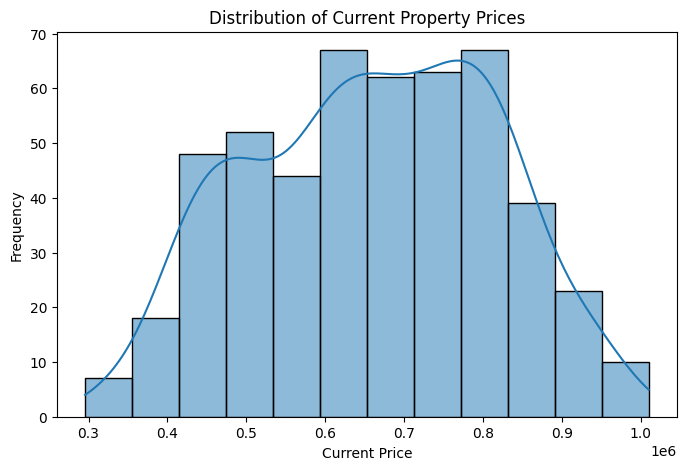

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Current_Price"],
    kde=True
)

plt.title("Distribution of Current Property Prices")
plt.xlabel("Current Price")
plt.ylabel("Frequency")

plt.show()

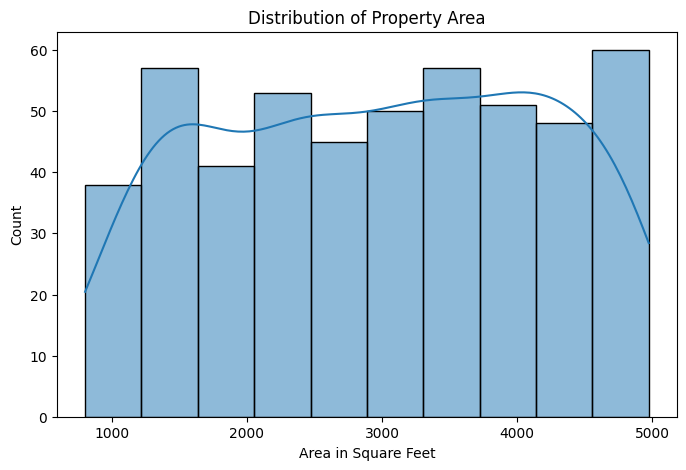

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Area_sqft"],
    kde=True
)

plt.title("Distribution of Property Area")
plt.xlabel("Area in Square Feet")

plt.show()

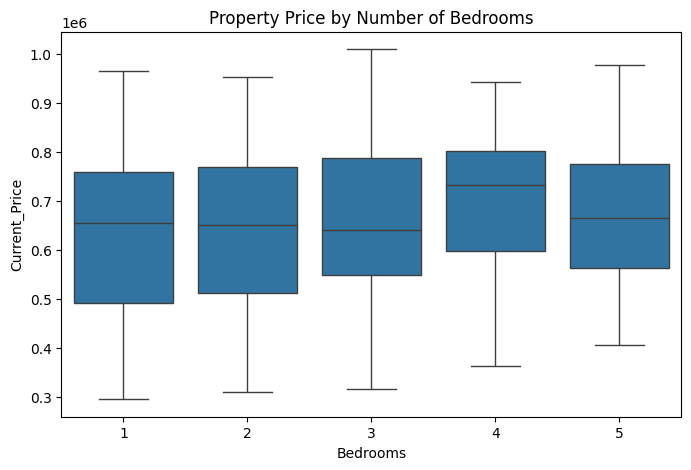

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Bedrooms",
    y="Current_Price"
)

plt.title("Property Price by Number of Bedrooms")

plt.show()

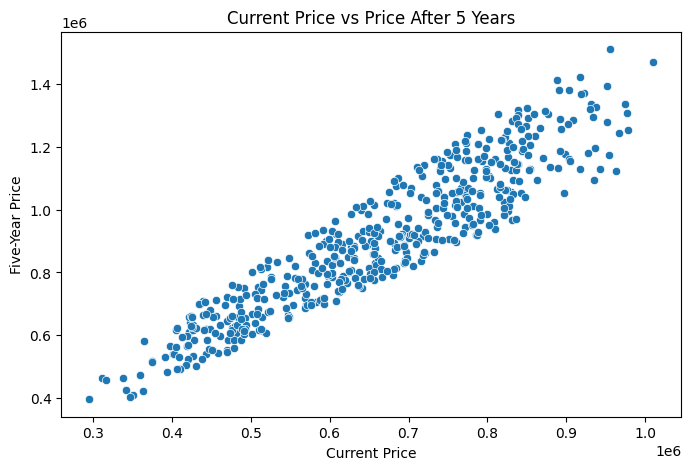

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Current_Price",
    y="Price_After_5_Years"
)

plt.title("Current Price vs Price After 5 Years")
plt.xlabel("Current Price")
plt.ylabel("Five-Year Price")

plt.show()

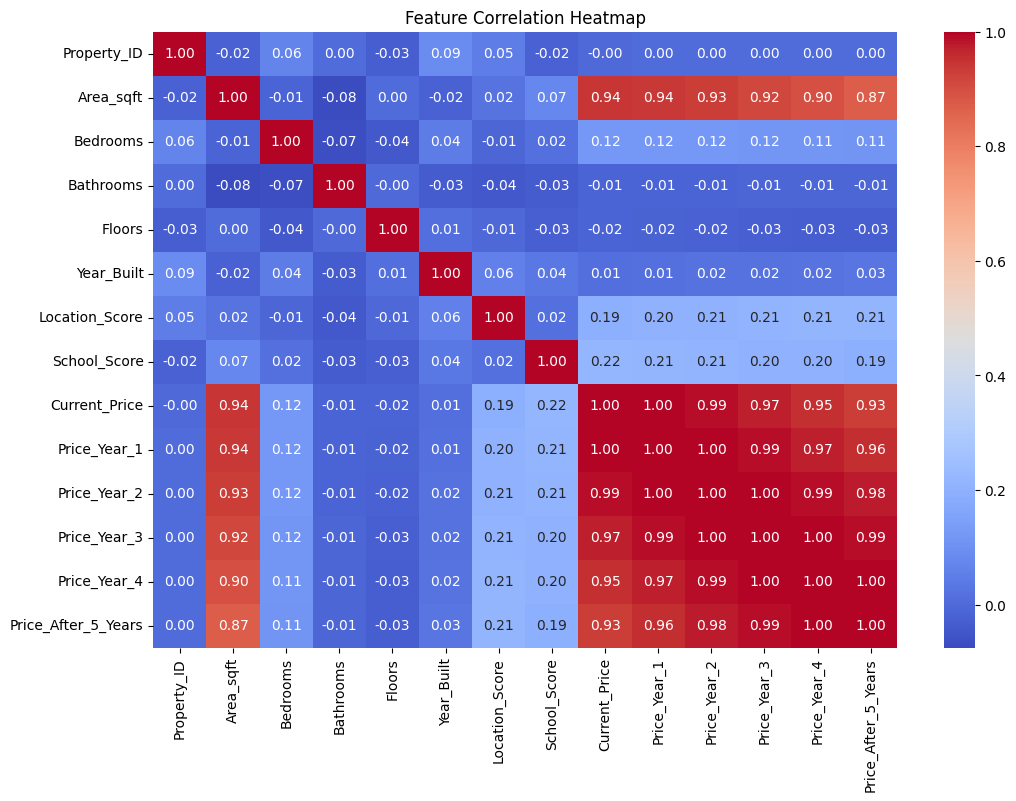

In [ ]:
plt.figure(figsize=(12,8))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [ ]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:")
print(df.shape)

Dataset shape after removing duplicates:
(500, 15)


In [ ]:
# Check missing values again
print(df.isnull().sum())

Property_ID            0
Area_sqft              0
Bedrooms               0
Bathrooms              0
Floors                 0
Year_Built             0
Location_Score         0
School_Score           0
Current_Price          0
Price_Year_1           0
Price_Year_2           0
Price_Year_3           0
Price_Year_4           0
Price_After_5_Years    0
Price_Category         0
dtype: int64


In [ ]:
numeric_columns = [
    "Area_sqft",
    "Bedrooms",
    "Bathrooms",
    "Floors",
    "Year_Built",
    "Location_Score",
    "School_Score",
    "Current_Price",
    "Price_Year_1",
    "Price_Year_2",
    "Price_Year_3",
    "Price_Year_4",
    "Price_After_5_Years"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.dtypes)

Property_ID             int64
Area_sqft               int64
Bedrooms                int64
Bathrooms               int64
Floors                  int64
Year_Built              int64
Location_Score          int64
School_Score            int64
Current_Price           int64
Price_Year_1            int64
Price_Year_2            int64
Price_Year_3            int64
Price_Year_4            int64
Price_After_5_Years     int64
Price_Category         object
dtype: object


In [ ]:
required_columns = [
    "Area_sqft",
    "Bedrooms",
    "Bathrooms",
    "Floors",
    "Year_Built",
    "Location_Score",
    "School_Score",
    "Current_Price",
    "Price_After_5_Years"
]

df = df.dropna(subset=required_columns)

df = df[
    (df["Area_sqft"] > 0) &
    (df["Current_Price"] > 0) &
    (df["Price_After_5_Years"] > 0)
].copy()

print("Clean dataset shape:", df.shape)

Clean dataset shape: (500, 15)


In [ ]:
CURRENT_YEAR = 2026

df["Property_Age"] = (
    CURRENT_YEAR - df["Year_Built"]
).clip(lower=0)

display(df[["Year_Built", "Property_Age"]].head())

,Year_Built,Property_Age
0,1989,37
1,2019,7
2,1989,37
3,2004,22
4,1987,39


In [ ]:
df["Price_Per_Sqft"] = (
    df["Current_Price"] / df["Area_sqft"]
)

display(
    df[[
        "Area_sqft",
        "Current_Price",
        "Price_Per_Sqft"
    ]].head()
)

,Area_sqft,Current_Price,Price_Per_Sqft
0,2751,624636,227.057797
1,3322,694237,208.981638
2,4765,771778,161.968101
3,4512,792597,175.664229
4,2436,580257,238.200739


In [ ]:
df["Five_Year_Appreciation"] = (
    df["Price_After_5_Years"] -
    df["Current_Price"]
)

display(
    df[[
        "Current_Price",
        "Price_After_5_Years",
        "Five_Year_Appreciation"
    ]].head()
)

,Current_Price,Price_After_5_Years,Five_Year_Appreciation
0,624636,803092,178456
1,694237,887363,193126
2,771778,945078,173300
3,792597,1154906,362309
4,580257,757525,177268


In [ ]:
df["ROI_5_Years"] = (
    df["Five_Year_Appreciation"] /
    df["Current_Price"]
) * 100

display(
    df[[
        "Current_Price",
        "Price_After_5_Years",
        "ROI_5_Years"
    ]].head()
)

,Current_Price,Price_After_5_Years,ROI_5_Years
0,624636,803092,28.569599
1,694237,887363,27.818454
2,771778,945078,22.454644
3,792597,1154906,45.711629
4,580257,757525,30.549912


In [ ]:
features = [
    "Area_sqft",
    "Bedrooms",
    "Bathrooms",
    "Floors",
    "Year_Built",
    "Location_Score",
    "School_Score",
    "Current_Price",
    "Property_Age",
    "Price_Per_Sqft"
]

X = df[features]

# Regression target
y_reg = df["Price_After_5_Years"]

# Continuous ROI used to create classification target
y_roi = df["ROI_5_Years"]

print("Input features:", X.columns.tolist())
print("Input shape:", X.shape)

Input features: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Location_Score', 'School_Score', 'Current_Price', 'Property_Age', 'Price_Per_Sqft']
Input shape: (500, 10)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train_reg, y_test_reg, roi_train, roi_test = train_test_split(
    X,
    y_reg,
    y_roi,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 400
Testing records: 100


In [ ]:
# Determine threshold using training data only
roi_threshold = roi_train.median()

y_train_class = (
    roi_train >= roi_threshold
).astype(int)

y_test_class = (
    roi_test >= roi_threshold
).astype(int)

print("ROI Threshold:", round(roi_threshold, 2), "%")

print("\nTraining target distribution:")
print(y_train_class.value_counts())

print("\nTesting target distribution:")
print(y_test_class.value_counts())

ROI Threshold: 36.7 %

Training target distribution:
ROI_5_Years
0    200
1    200
Name: count, dtype: int64

Testing target distribution:
ROI_5_Years
0    55
1    45
Name: count, dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
preprocessor = SimpleImputer(
    strategy="median"
)

In [ ]:
classification_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

In [ ]:
classification_results = []
trained_classifiers = {}

for name, algorithm in classification_models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train_class)

    predictions = pipeline.predict(X_test)

    probabilities = pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(
        y_test_class, predictions
    )

    precision = precision_score(
        y_test_class, predictions, zero_division=0
    )

    recall = recall_score(
        y_test_class, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test_class, predictions, zero_division=0
    )

    auc = roc_auc_score(
        y_test_class, probabilities
    )

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": auc
    })

    trained_classifiers[name] = pipeline

classification_results_df = pd.DataFrame(
    classification_results
)

display(
    classification_results_df.sort_values(
        by="ROC AUC",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
1,Extra Trees,0.50,0.456140,0.577778,0.509804,0.510101
0,Random Forest,0.49,0.444444,0.533333,0.484848,0.488283
2,Gradient Boosting,0.47,0.431034,0.555556,0.485437,0.463030


In [ ]:
best_classifier_name = (
    classification_results_df
    .sort_values("ROC AUC", ascending=False)
    .iloc[0]["Model"]
)

best_classifier = trained_classifiers[
    best_classifier_name
]

print("Best Classification Model:", best_classifier_name)

Best Classification Model: Extra Trees


In [ ]:
class_predictions = best_classifier.predict(X_test)

print(
    classification_report(
        y_test_class,
        class_predictions,
        target_names=[
            "Not a Good Investment",
            "Good Investment"
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

Not a Good Investment       0.56      0.44      0.49        55
      Good Investment       0.46      0.58      0.51        45

             accuracy                           0.50       100
            macro avg       0.51      0.51      0.50       100
         weighted avg       0.51      0.50      0.50       100



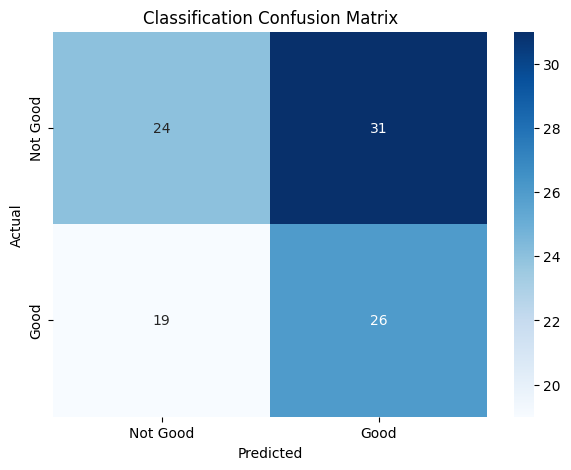

In [ ]:
cm = confusion_matrix(
    y_test_class,
    class_predictions
)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Good",
        "Good"
    ],
    yticklabels=[
        "Not Good",
        "Good"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Classification Confusion Matrix")

plt.show()

In [ ]:
regression_models = {

    "Random Forest": RandomForestRegressor(
        n_estimators=400,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=400,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

In [ ]:
regression_results = []

trained_regressors = {}

for name, algorithm in regression_models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", algorithm)
    ])

    pipeline.fit(
        X_train,
        y_train_reg
    )

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(
        y_test_reg,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_reg,
            predictions
        )
    )

    r2 = r2_score(
        y_test_reg,
        predictions
    )

    regression_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_regressors[name] = pipeline

regression_results_df = pd.DataFrame(
    regression_results
)

display(
    regression_results_df.sort_values(
        by="MAE"
    )
)

,Model,MAE,RMSE,R2 Score
2,Gradient Boosting,78403.294751,94863.665517,0.830208
0,Random Forest,80158.314575,98949.747433,0.815266
1,Extra Trees,80566.411000,97667.612049,0.820023


In [ ]:
best_regressor_name = (
    regression_results_df
    .sort_values("MAE")
    .iloc[0]["Model"]
)

best_regressor = trained_regressors[
    best_regressor_name
]

print("Best Regression Model:", best_regressor_name)

Best Regression Model: Gradient Boosting


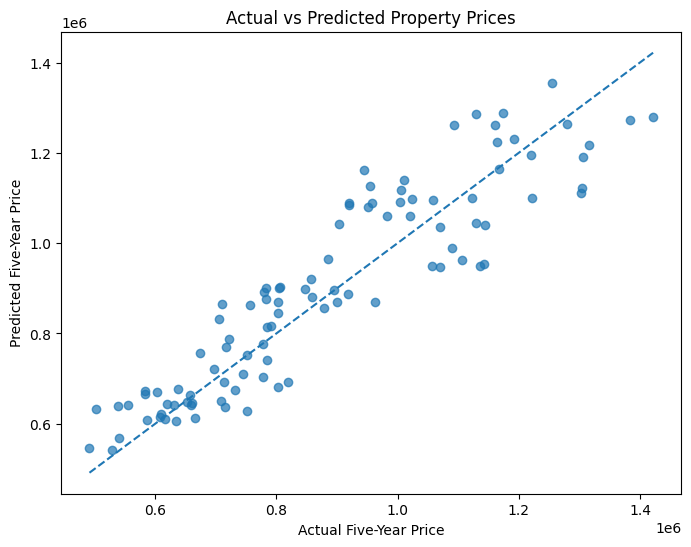

In [ ]:
reg_predictions = best_regressor.predict(X_test)

plt.figure(figsize=(8,6))

plt.scatter(
    y_test_reg,
    reg_predictions,
    alpha=0.7
)

minimum = min(y_test_reg.min(), reg_predictions.min())
maximum = max(y_test_reg.max(), reg_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Five-Year Price")
plt.ylabel("Predicted Five-Year Price")

plt.title("Actual vs Predicted Property Prices")

plt.show()

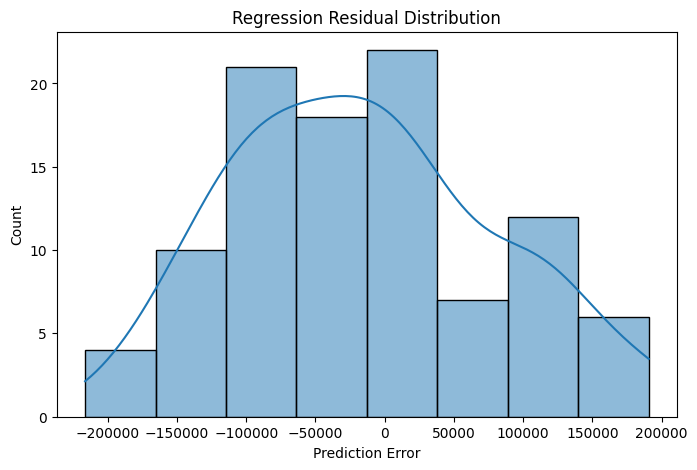

In [ ]:
residuals = y_test_reg - reg_predictions

plt.figure(figsize=(8,5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Regression Residual Distribution")
plt.xlabel("Prediction Error")

plt.show()

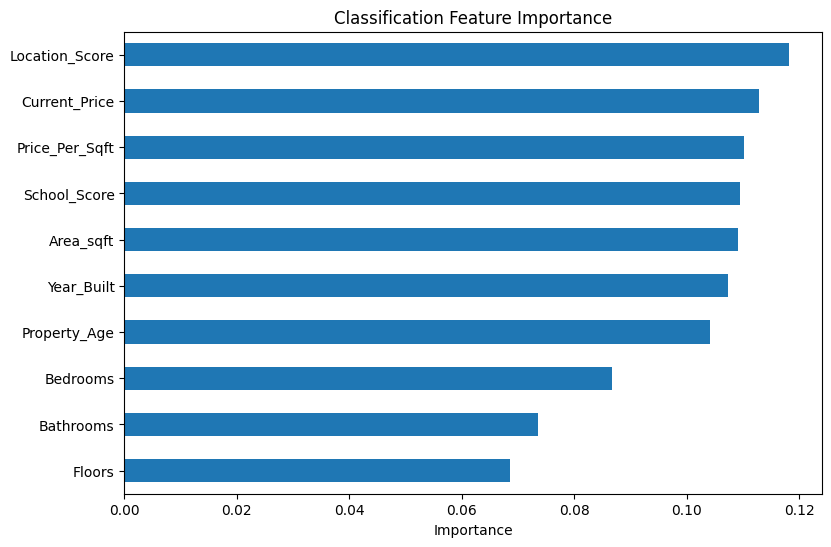

In [ ]:
importance = pd.Series(
    best_classifier.named_steps["model"].feature_importances_,
    index=features
).sort_values(ascending=False)

plt.figure(figsize=(9,6))

importance.plot(kind="barh")

plt.title("Classification Feature Importance")
plt.xlabel("Importance")

plt.gca().invert_yaxis()

plt.show()

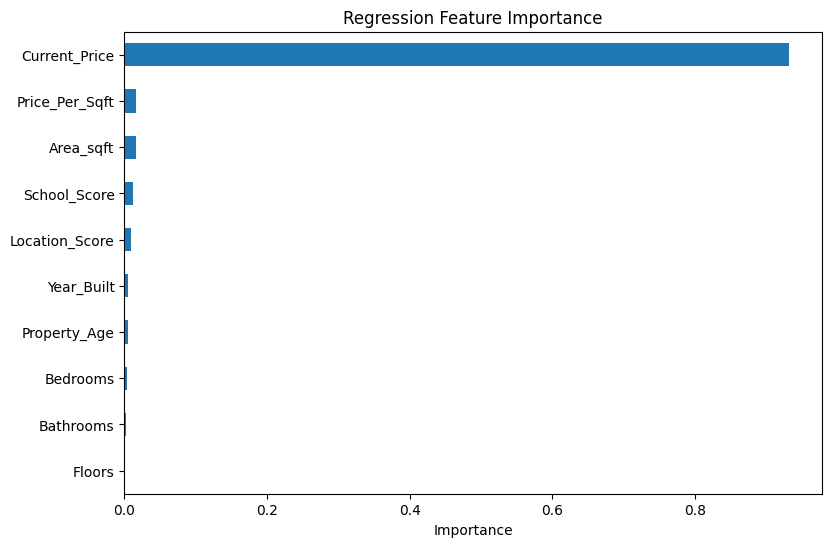

In [ ]:
importance_reg = pd.Series(
    best_regressor.named_steps["model"].feature_importances_,
    index=features
).sort_values(ascending=False)

plt.figure(figsize=(9,6))

importance_reg.plot(kind="barh")

plt.title("Regression Feature Importance")
plt.xlabel("Importance")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
!pip install -q mlflow

In [ ]:
import os
# Allow MLflow to use local filesystem store
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("file:/content/mlruns")

mlflow.set_experiment(
    "Real_Estate_Investment_Prediction"
)

print("MLflow initialized successfully!")

2026/11/02 05:39:48 INFO mlflow.tracking.fluent: Experiment with name 'Real_Estate_Investment_Prediction' does not exist. Creating a new experiment.


MLflow initialized successfully!


In [ ]:
for name, model in trained_classifiers.items():

    row = classification_results_df[
        classification_results_df["Model"] == name
    ].iloc[0]

    with mlflow.start_run(run_name=f"Classification_{name}"):

        mlflow.log_param("algorithm", name)
        mlflow.log_param("problem_type", "Classification")
        mlflow.log_param("test_size", 0.20)
        mlflow.log_param("random_state", 42)
        mlflow.log_param("roi_threshold", float(roi_threshold))

        for metric in [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "ROC AUC"
        ]:
            mlflow.log_metric(
                metric.lower().replace(" ", "_"),
                float(row[metric])
            )

        mlflow.sklearn.log_model(
            model,
            artifact_path="classification_model",
            skops_trusted_types=["numpy.dtype", "sklearn.tree._tree.Tree"]
        )

print("Classification experiments logged!")

2026/11/02 05:40:23 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/02 05:40:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/02 05:40:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Classification experiments logged!


In [ ]:
for name, model in trained_regressors.items():

    row = regression_results_df[
        regression_results_df["Model"] == name
    ].iloc[0]

    with mlflow.start_run(run_name=f"Regression_{name}"):

        mlflow.log_param("algorithm", name)
        mlflow.log_param("problem_type", "Regression")
        mlflow.log_param("test_size", 0.20)
        mlflow.log_param("random_state", 42)

        mlflow.log_metric("mae", float(row["MAE"]))
        mlflow.log_metric("rmse", float(row["RMSE"]))
        mlflow.log_metric("r2_score", float(row["R2 Score"]))

        mlflow.sklearn.log_model(
            model,
            artifact_path="regression_model",
            skops_trusted_types=["numpy.dtype", "sklearn.tree._tree.Tree"]
        )

print("Regression experiments logged!")

2026/11/02 05:41:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/02 05:41:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/02 05:41:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Regression experiments logged!


In [ ]:
!mlflow ui --backend-store-uri /content/mlruns --host 0.0.0.0 --port 5000 > /content/mlflow.log 2>&1 &

In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
added 22 packages in 4s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴

In [ ]:
!nohup lt --host https://loca.lt --port 5000 > /content/localtunnel.log 2>&1 &

import time
time.sleep(5)

print("Localtunnel output:")
!cat /content/localtunnel.log

Localtunnel output:
your url is: https://social-zoos-carry.loca.lt


In [ ]:
import os

os.makedirs(
    "/content/real_estate_models",
    exist_ok=True
)

print("Folder created!")

Folder created!


In [ ]:
import joblib

joblib.dump(
    best_classifier,
    "/content/real_estate_models/classification_model.pkl"
)

joblib.dump(
    best_regressor,
    "/content/real_estate_models/regression_model.pkl"
)

print("Both models saved successfully!")

Both models saved successfully!


In [ ]:
import json

metadata = {
    "features": features,
    "roi_threshold": float(roi_threshold),
    "year_reference": CURRENT_YEAR,
    "classification_model": best_classifier_name,
    "regression_model": best_regressor_name
}

with open(
    "/content/real_estate_models/metadata.json",
    "w"
) as f:

    json.dump(metadata, f, indent=4)

print("Model configuration saved!")

Model configuration saved!


In [ ]:
new_property = pd.DataFrame([{

    "Area_sqft": 2500,
    "Bedrooms": 3,
    "Bathrooms": 2,
    "Floors": 2,
    "Year_Built": 2018,
    "Location_Score": 80,
    "School_Score": 75,
    "Current_Price": 650000,

    "Property_Age": CURRENT_YEAR - 2018,

    "Price_Per_Sqft": 650000 / 2500

}])

new_property = new_property[features]

display(new_property)

,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location_Score,School_Score,Current_Price,Property_Age,Price_Per_Sqft
0,2500,3,2,2,2018,80,75,650000,8,260.0


In [ ]:
prediction = best_classifier.predict(
    new_property
)[0]

probability = best_classifier.predict_proba(
    new_property
)[0][1]

if prediction == 1:

    print("Recommendation: GOOD INVESTMENT")

else:

    print("Recommendation: NOT A GOOD INVESTMENT")

print(
    "Good Investment Model Probability:",
    round(probability * 100, 2),
    "%"
)

Recommendation: GOOD INVESTMENT
Good Investment Model Probability: 57.0 %


In [ ]:
predicted_price = best_regressor.predict(
    new_property
)[0]

current_price = 650000

appreciation = predicted_price - current_price

roi = (
    appreciation / current_price
) * 100

print("Current Price:", current_price)

print(
    "Predicted Price After 5 Years:",
    round(predicted_price, 2)
)

print(
    "Expected Appreciation:",
    round(appreciation, 2)
)

print(
    "Estimated Five-Year ROI:",
    round(roi, 2),
    "%"
)

Current Price: 650000
Predicted Price After 5 Years: 887797.73
Expected Appreciation: 237797.73
Estimated Five-Year ROI: 36.58 %


In [ ]:
!pip install -q streamlit

In [19]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
import json

st.set_page_config(
    page_title="Real Estate Investment Advisor",
    page_icon="🏡",
    layout="wide"
)

# Load saved models
classifier = joblib.load(
    "/content/real_estate_models/classification_model.pkl"
)

regressor = joblib.load(
    "/content/real_estate_models/regression_model.pkl"
)

with open(
    "/content/real_estate_models/metadata.json"
) as f:

    metadata = json.load(f)

features = metadata["features"]
CURRENT_YEAR = metadata["year_reference"]

# Application heading
st.title("🏡 Real Estate Investment Advisor")

st.write(
    "Evaluate property investments using Machine Learning."
)

st.divider()

st.sidebar.header("Enter Property Details")

# User inputs
area = st.sidebar.number_input(
    "Property Area (sq. ft.)",
    min_value=100,
    value=2500
)

bedrooms = st.sidebar.number_input(
    "Bedrooms",
    min_value=1,
    value=3
)

bathrooms = st.sidebar.number_input(
    "Bathrooms",
    min_value=1,
    value=2
)

floors = st.sidebar.number_input(
    "Floors",
    min_value=1,
    value=2
)

year_built = st.sidebar.number_input(
    "Year Built",
    min_value=1900,
    max_value=CURRENT_YEAR,
    value=2018
)

location_score = st.sidebar.slider(
    "Location Score",
    0, 100, 80
)

school_score = st.sidebar.slider(
    "School Score",
    0, 100, 75
)

current_price = st.sidebar.number_input(
    "Current Property Price",
    min_value=10000,
    value=650000
)

# Prediction button
if st.sidebar.button(
    "Analyze Investment",
    type="primary"
):

    # Feature engineering
    property_age = max(
        0,
        CURRENT_YEAR - year_built
    )

    price_per_sqft = current_price / area

    input_data = pd.DataFrame([{

        "Area_sqft": area,
        "Bedrooms": bedrooms,
        "Bathrooms": bathrooms,
        "Floors": floors,
        "Year_Built": year_built,
        "Location_Score": location_score,
        "School_Score": school_score,
        "Current_Price": current_price,
        "Property_Age": property_age,
        "Price_Per_Sqft": price_per_sqft

    }])

    input_data = input_data[features]

    # Classification
    investment_prediction = classifier.predict(
        input_data
    )[0]

    investment_probability = classifier.predict_proba(
        input_data
    )[0][1]

    # Regression
    future_price = regressor.predict(
        input_data
    )[0]

    # ROI calculation
    appreciation = future_price - current_price

    roi = (
        appreciation / current_price
    ) * 100

    # Display results
    st.subheader("Investment Analysis")

    col1, col2, col3 = st.columns(3)

    with col1:

        st.metric(
            "Current Property Price",
            f"{current_price:,.2f}"
        )

    with col2:

        st.metric(
            "Estimated 5-Year Price",
            f"{future_price:,.2f}"
        )

    with col3:

        st.metric(
            "Estimated ROI",
            f"{roi:.2f}%"
        )

    st.divider()

    st.subheader("Investment Classification")

    if investment_prediction == 1:

        st.success("GOOD INVESTMENT")

    else:

        st.warning("NOT A GOOD INVESTMENT")

    st.write(
        "Good Investment Model Probability:",
        f"{investment_probability * 100:.2f}%"
    )

    st.progress(
        float(investment_probability)
    )

    st.subheader("Five-Year Price Forecast")

    st.write(
        "Expected Property Appreciation:",
        f"{appreciation:,.2f}"
    )

    st.write(
        "Estimated Five-Year ROI:",
        f"{roi:.2f}%"
    )

    st.caption(
        "This is an educational machine learning prediction. "
        "Actual property prices may differ. "
        "The model does not include rental yield, taxes, "
        "maintenance, financing costs or transaction costs."
    )

else:

    st.info(
        "Enter property details in the sidebar "
        "and click Analyze Investment."
    )

Writing app.py


In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇
changed 22 packages in 2s
⠇
⠇3 packages are looking for funding
⠇  run `npm fund` for details
⠇

In [1]:
!nohup lt --host https://loca.lt --port 8501 > /content/streamlit_tunnel.log 2>&1 &

import time
time.sleep(5)

print("Streamlit Localtunnel Output:")
!cat /content/streamlit_tunnel.log

Streamlit Localtunnel Output:
nohup: failed to run command 'lt': No such file or directory


In [2]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [3]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏
added 22 packages in 2s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏

In [10]:
!streamlit run app.py --server.address=localhost &>/content/logs.txt &


In [13]:
!nohup npx localtunnel --host https://loca.lt --port 8501 > /content/streamlit_tunnel.log 2>&1 &

import time
time.sleep(5)

print("Streamlit Tunnel Output:")
!cat /content/streamlit_tunnel.log

Streamlit Tunnel Output:
your url is: https://ten-ends-roll.loca.lt


In [14]:
!streamlit run app.py &>/content/streamlit.log &


In [15]:
!cat /content/streamlit.log

/bin/bash: line 1: streamlit: command not found


In [16]:
!pip install -q streamlit

In [17]:
!python -m streamlit --version

Streamlit, version 1.66.1


In [23]:
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [24]:
import shutil

shutil.make_archive(
    "/content/Real_Estate_Investment_Project",
    "zip",
    "/content",
    "real_estate_models"
)

print("Project folder zipped successfully!")

Project folder zipped successfully!


In [25]:
from google.colab import files

files.download(
    "/content/Real_Estate_Investment_Project.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>